# Categorical combination space in no-alarm `{y_prob <= 0.02}`

The neighbors notebook asks, for each fraud, which rows share all of its categorical values. This notebook measures the space those footprints live in:

1. unique values per categorical column,
2. total combinations for all categorical columns together (the full grid vs what actually occurs),
3. unique combinations when one column is dropped (all single drops), and when two columns are dropped (all pairs).

The two time columns count as categorical here: `time_of_day_hour` (up to 24 values) and `day_of_week` (7), up to 168 combinations on their own. The five alarm flags are expected to be constant in this region, so they cannot split any cell; the counts below show that directly.


In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "no_alarm_p_le_002_cat_combinations"
EXP_NAME = "hgb_baseline"
PROB_COL = "y_prob"
FOLD_COL = "fold_id"
SCORE_CUT = 0.02
TIME_COLUMNS = ("time_of_day_hour", "day_of_week")
CAT_COLS = list(CATEGORICAL_COLUMNS) + list(TIME_COLUMNS)
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
train_features = train_df.drop(columns=[TARGET_COLUMN])
frame = train_features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
if len(frame) != len(train_df) or len(frame) != len(oof_df):
    raise ValueError(
        f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
    )
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
region = frame.loc[(~has_alarm) & (frame[PROB_COL] <= SCORE_CUT)].copy()
print("n_region", len(region))
print("n_cat_columns", len(CAT_COLS))
print("cat columns", CAT_COLS)


n_region 590070
n_cat_columns 13
cat columns ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'time_of_day_hour', 'day_of_week']


## Unique values per categorical column

`n_unique` inside the region of interest only. A constant column multiplies the grid by 1 and splits nothing.


In [2]:
fraud_mask = region[TARGET_COLUMN] == 1
n_fraud_region = int(fraud_mask.sum())
rate_region = n_fraud_region / len(region)
print("n_region", len(region))
print("n_fraud_region", n_fraud_region)
print("rate_region", round(rate_region, 6))
print(DELIMITER_VALUE)

n_cat = len(CAT_COLS)
unique_rows: list[dict[str, object] | None] = [None] * n_cat
for i in range(n_cat):
    name = CAT_COLS[i]
    n_unique = int(region[name].nunique())
    unique_rows[i] = {
        "column": name,
        "n_unique": n_unique,
        "is_constant": n_unique == 1,
    }
unique_table = pd.DataFrame([row for row in unique_rows if row is not None])
unique_table = unique_table.sort_values("n_unique", ascending=False).reset_index(drop=True)
print(unique_table.to_string(index=False))
n_unique_by_col = dict(
    zip(unique_table["column"].astype(str), unique_table["n_unique"].astype(int))
)
constant_columns = unique_table.loc[unique_table["is_constant"], "column"].tolist()
print(DELIMITER_VALUE)
print("constant columns in region:", constant_columns)
unique_path = tables_dir / "per_column_unique.csv"
unique_table.to_csv(unique_path, index=False)
print("saved", unique_path)


n_region 590070
n_fraud_region 1674
rate_region 0.002837
--------------------------------------------------
                      column  n_unique  is_constant
            time_of_day_hour        24        False
           merchant_category        12        False
                 device_type         8        False
                 day_of_week         7        False
                   card_type         5        False
                     channel         5        False
                 auth_method         5        False
             is_new_merchant         2        False
      is_foreign_transaction         1         True
         ip_country_mismatch         1         True
                    used_vpn         1         True
is_ai_generated_scam_attempt         1         True
   billing_shipping_mismatch         1         True
--------------------------------------------------
constant columns in region: ['is_foreign_transaction', 'ip_country_mismatch', 'used_vpn', 'is_ai_generated_scam_a

## All categorical columns together

- **theoretical**: product of the unique counts, the size of the full grid.
- **observed**: unique combinations that actually occur among the region rows.
- **density**: observed / theoretical.

`cell_sizes` is how many rows sit behind one combination. Thin cells are what make a footprint look like "1 fraud + tens of non-frauds": with enough splitting columns, every row lands in its own small corner. Columns are factorized to integer codes first; all counts run on the codes.


In [3]:
codes = pd.DataFrame(index=region.index)
for i in range(n_cat):
    name = CAT_COLS[i]
    codes[name], _ = pd.factorize(region[name])
fraud_codes = codes.loc[fraud_mask]
if len(fraud_codes) != n_fraud_region:
    raise ValueError("fraud code count mismatch")

theoretical_total = 1
for i in range(n_cat):
    theoretical_total *= n_unique_by_col[CAT_COLS[i]]
n_observed = len(codes.drop_duplicates(ignore_index=True))
n_fraud_observed = len(fraud_codes.drop_duplicates(ignore_index=True))
cell_sizes = codes.groupby(list(CAT_COLS)).size()

full_row: dict[str, object] = {
    "n_columns": n_cat,
    "theoretical_total": theoretical_total,
    "n_observed_cells": n_observed,
    "density": n_observed / theoretical_total,
    "n_fraud_observed_cells": n_fraud_observed,
    "median_cell_size": float(cell_sizes.median()),
    "mean_cell_size": float(cell_sizes.mean()),
    "share_cells_singleton": float((cell_sizes == 1).mean()),
    "n_rows_in_singleton_cells": int((cell_sizes == 1).sum()),
}
full_table = pd.DataFrame([full_row])
print(full_table.transpose().to_string())
print(DELIMITER_VALUE)
print("cell size percentiles")
print(cell_sizes.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_string())
full_path = tables_dir / "full_combination_space.csv"
full_table.to_csv(full_path, index=False)
print("saved", full_path)


                                      0
n_columns                  1.300000e+01
theoretical_total          4.032000e+06
n_observed_cells           3.469000e+05
density                    8.603671e-02
n_fraud_observed_cells     1.669000e+03
median_cell_size           1.000000e+00
mean_cell_size             1.700980e+00
share_cells_singleton      6.845200e-01
n_rows_in_singleton_cells  2.374600e+05
--------------------------------------------------
cell size percentiles
count    346900.00000
mean          1.70098
std           1.53972
min           1.00000
25%           1.00000
50%           1.00000
75%           2.00000
90%           3.00000
99%           9.00000
max          26.00000
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_combinations\tables\full_combination_space.csv


## Drop one column (leave-one-out)

Dropping column X merges every pair of cells that differ only on X. If the observed count collapses, X was doing most of the splitting. `merge_factor` is `n_observed_cells(all) / n_observed_cells(without X)`. Dropping a constant alarm flag changes nothing.


In [4]:
loo_rows: list[dict[str, object] | None] = [None] * n_cat
for i in range(n_cat):
    dropped = CAT_COLS[i]
    kept = [name for name in CAT_COLS if name != dropped]
    theoretical_i = 1
    for name in kept:
        theoretical_i *= n_unique_by_col[name]
    loo_rows[i] = {
        "dropped": dropped,
        "theoretical_total": theoretical_i,
        "n_observed_cells": len(codes[kept].drop_duplicates(ignore_index=True)),
        "n_fraud_observed_cells": len(
            fraud_codes[kept].drop_duplicates(ignore_index=True)
        ),
    }
loo_table = pd.DataFrame([row for row in loo_rows if row is not None])
loo_table["drop_in_observed"] = n_observed - loo_table["n_observed_cells"]
loo_table["merge_factor"] = n_observed / loo_table["n_observed_cells"]
loo_table = loo_table.sort_values("n_observed_cells").reset_index(drop=True)
print(loo_table.to_string(index=False))
loo_path = tables_dir / "leave_one_out_combinations.csv"
loo_table.to_csv(loo_path, index=False)
print("saved", loo_path)


                     dropped  theoretical_total  n_observed_cells  n_fraud_observed_cells  drop_in_observed  merge_factor
            time_of_day_hour             168000             72255                    1601            274645      4.801052
           merchant_category             336000            129568                    1641            217332      2.677359
                 day_of_week             576000            151113                    1650            195787      2.295633
                 device_type             504000            161650                    1659            185250      2.145994
                 auth_method             806400            187272                    1659            159628      1.852386
                     channel             806400            195398                    1663            151502      1.775351
                   card_type             806400            222332                    1659            124568      1.560279
             is_new_merc

## Drop two columns (leave-two-out)

Every pair. The smallest observed counts show which pair carries the explosion. A pair containing a constant alarm flag equals the single drop of the other column.


In [5]:
n_pairs = n_cat * (n_cat - 1) // 2
pair_rows: list[dict[str, object] | None] = [None] * n_pairs
row_i = 0
for i in range(n_cat):
    for j in range(i + 1, n_cat):
        kept = [
            name
            for k, name in enumerate(CAT_COLS)
            if k != i and k != j
        ]
        pair_rows[row_i] = {
            "dropped_1": CAT_COLS[i],
            "dropped_2": CAT_COLS[j],
            "n_observed_cells": len(codes[kept].drop_duplicates(ignore_index=True)),
            "n_fraud_observed_cells": len(
                fraud_codes[kept].drop_duplicates(ignore_index=True)
            ),
        }
        row_i += 1
if row_i != n_pairs:
    raise ValueError(f"pair count mismatch: {row_i} vs {n_pairs}")
pair_table = pd.DataFrame([row for row in pair_rows if row is not None])
pair_table["merge_factor"] = n_observed / pair_table["n_observed_cells"]
pair_table = pair_table.sort_values("n_observed_cells").reset_index(drop=True)
print("smallest observed counts (strongest collapse)")
print(pair_table.head(12).to_string(index=False))
print(DELIMITER_VALUE)
print("largest observed counts (weakest collapse)")
print(pair_table.tail(3).to_string(index=False))
pair_path = tables_dir / "leave_two_out_combinations.csv"
pair_table.to_csv(pair_path, index=False)
print("saved", pair_path)


smallest observed counts (strongest collapse)
        dropped_1        dropped_2  n_observed_cells  n_fraud_observed_cells  merge_factor
merchant_category time_of_day_hour             11981                    1268     28.954177
      device_type time_of_day_hour             16478                    1397     21.052312
 time_of_day_hour      day_of_week             16897                    1305     20.530272
      auth_method time_of_day_hour             23006                    1391     15.078675
          channel time_of_day_hour             23581                    1442     14.710996
        card_type time_of_day_hour             25690                    1481     13.503309
merchant_category      device_type             33334                    1562     10.406792
merchant_category      day_of_week             33570                    1513     10.333631
      device_type      day_of_week             44490                    1567      7.797258
merchant_category      auth_method          

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_combinations\plots\combination_space\combination_space_collapse.png


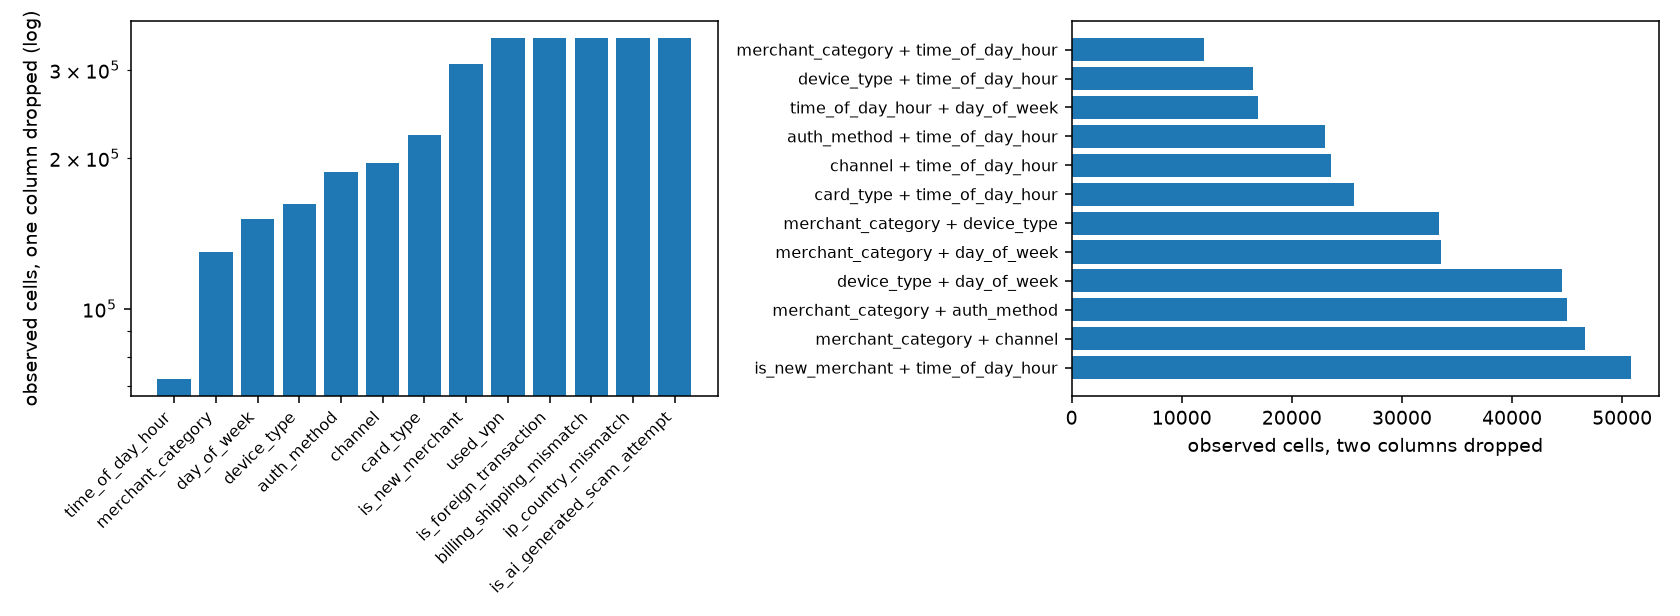

In [6]:
plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="combination_space")
fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4))
axes[0].bar(
    np.arange(len(loo_table)),
    loo_table["n_observed_cells"].to_numpy(dtype=np.float64),
)
axes[0].set_xticks(np.arange(len(loo_table)))
axes[0].set_xticklabels(list(loo_table["dropped"]), rotation=45, ha="right", fontsize=8)
axes[0].set_yscale("log")
axes[0].set_ylabel("observed cells, one column dropped (log)")
best_pairs = pair_table.head(12).copy()
best_pairs["dropped"] = best_pairs["dropped_1"] + " + " + best_pairs["dropped_2"]
order = np.arange(len(best_pairs))[::-1]
axes[1].barh(
    order,
    best_pairs["n_observed_cells"].to_numpy(dtype=np.float64),
)
axes[1].set_yticks(order)
axes[1].set_yticklabels(list(best_pairs["dropped"]), fontsize=8)
axes[1].set_xlabel("observed cells, two columns dropped")
fig.tight_layout()
plot_path = plot_dir / "combination_space_collapse.png"
fig.savefig(plot_path, dpi=140)
print("saved", plot_path)


## Takeaway

Region: **590,070** rows, **1,674** frauds (rate 0.28%). The five alarm flags are constant here, so 8 of the 13 columns can actually split cells.

1. **At full width the categorical footprint is row-level, not a footprint.** Theoretical grid **4.03M** cells, observed **346,900**, mean **1.7** rows per cell, **68%** of cells are singletons holding 237k rows (40% of the region). **1,669** of the 1,674 frauds have a footprint no other row shares. With 13 columns nothing groups: the "1 fraud + tens of non-frauds" pattern cannot even form at this width.

2. **The time columns are the biggest splitters, as suspected.** Dropping `time_of_day_hour` alone collapses 346.9k to **72.3k** cells (merge x4.8). Dropping both hour and `day_of_week`: **16.9k** cells (x20.5), about 35 rows per cell. Next: `day_of_week` alone (x2.3), `merchant_category` (x2.7), `device_type` (x2.1). `is_new_merchant` splits almost nothing (x1.13).

3. **Constant columns are exact no-ops.** Every alarm-flag drop leaves 346,900 cells and merge factor 1.0.

4. **Reading for the neighbors analysis.** Its fingerprint (6 varying columns, no time) sits at the coarse end: median fraud cell 113 rows. Any footprint query that adds the time columns must bucket them first (night/day, weekday/weekend), or the cells degenerate to near row-level. The pair table is the dial: pick a target number of cells and read off which columns to drop (merchant_category + hour -> 12k cells, both time columns -> 17k cells).

## Time cells: day_of_week x time_of_day_hour

Three heatmaps of the 7 x 24 grid: fraud counts, non-fraud counts, and fraud rate. The rate panel is centered on the region rate (0.28%), so red is more fraudulent than the region, blue less. The grid holds ~3.5k rows and ~10 frauds per cell on average, so single-cell rates are noisy: read clusters, not lone cells. The chi-square test on the same grid says whether fraud and the time cell are related at all.


fraud vs 7x24 time cell (chi-square independence)
chi2=150.0 dof=167 p=0.8232 cramers_v=0.0159
--------------------------------------------------
highest-rate cells
 day_of_week  hour  n_fraud    n     rate
           1     6       20 3424 0.005841
           2    15       22 4107 0.005357
           5    12       17 3340 0.005090
           2    16       17 3393 0.005010
           1    11       17 3467 0.004903
--------------------------------------------------
lowest-rate cells
 day_of_week  hour  n_fraud    n     rate
           1    20        4 3941 0.001015
           3     7        4 3526 0.001134
           1    13        5 4124 0.001212
           4     0        4 3193 0.001253
           1     4        5 3403 0.001469
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_combinations\tables\time_cell_fraud_rate.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\a

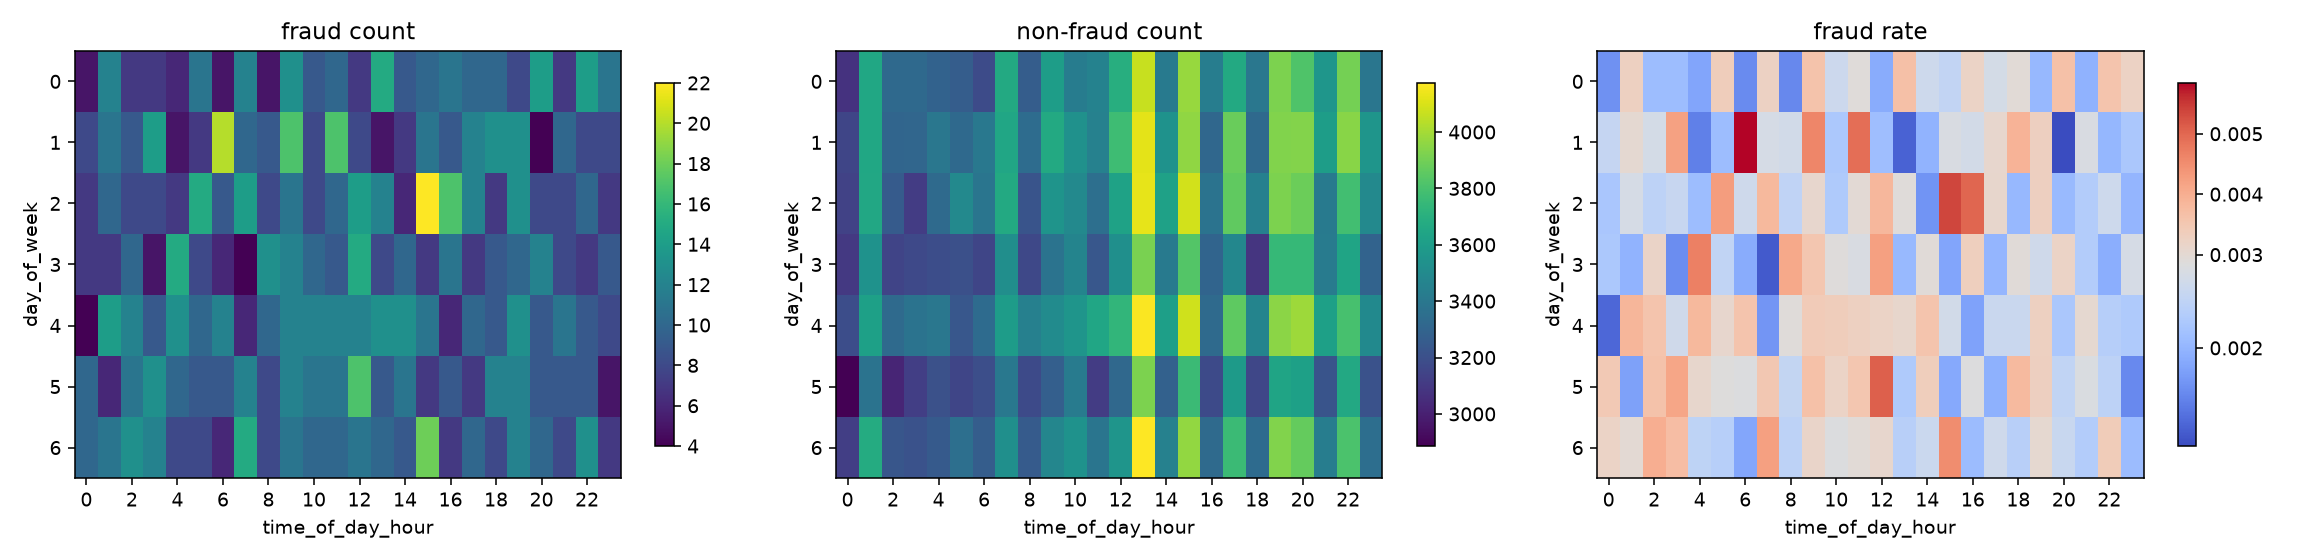

In [7]:
HOUR_COL = TIME_COLUMNS[0]
DOW_COL = TIME_COLUMNS[1]

fraud_part = region.loc[fraud_mask]
nonfraud_part = region.loc[~fraud_mask]
fraud_by_cell = (
    pd.crosstab(fraud_part[DOW_COL], fraud_part[HOUR_COL])
    .reindex(index=range(7), columns=range(24), fill_value=0)
)
nonfraud_by_cell = (
    pd.crosstab(nonfraud_part[DOW_COL], nonfraud_part[HOUR_COL])
    .reindex(index=range(7), columns=range(24), fill_value=0)
)
if int(fraud_by_cell.to_numpy().sum()) != n_fraud_region:
    raise ValueError("fraud cell counts do not sum to region fraud count")
if int(nonfraud_by_cell.to_numpy().sum()) != len(region) - n_fraud_region:
    raise ValueError("non-fraud cell counts do not sum to region non-fraud count")
total_by_cell = fraud_by_cell + nonfraud_by_cell
rate_by_cell = fraud_by_cell / total_by_cell

from scipy.stats import chi2_contingency

table_2x168 = np.vstack(
    [fraud_by_cell.to_numpy().ravel(), nonfraud_by_cell.to_numpy().ravel()]
)
chi2, p_value, dof, _ = chi2_contingency(table_2x168)
cramers_v = float(np.sqrt(chi2 / len(region)))
print("fraud vs 7x24 time cell (chi-square independence)")
print(f"chi2={chi2:.1f} dof={dof} p={p_value:.4g} cramers_v={cramers_v:.4f}")
print(DELIMITER_VALUE)

cell_table = (
    rate_by_cell.stack()
    .to_frame("rate")
    .join(total_by_cell.stack().to_frame("n"))
    .join(fraud_by_cell.stack().to_frame("n_fraud"))
    .reset_index()
    .rename(columns={DOW_COL: "day_of_week", HOUR_COL: "hour"})
)
print("highest-rate cells")
print(
    cell_table.sort_values("rate", ascending=False)
    .head(5)[["day_of_week", "hour", "n_fraud", "n", "rate"]]
    .to_string(index=False)
)
print(DELIMITER_VALUE)
print("lowest-rate cells")
print(
    cell_table.sort_values("rate")
    .head(5)[["day_of_week", "hour", "n_fraud", "n", "rate"]]
    .to_string(index=False)
)
cell_path = tables_dir / "time_cell_fraud_rate.csv"
cell_table.to_csv(cell_path, index=False)
print("saved", cell_path)

from matplotlib.colors import TwoSlopeNorm

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="time_cells")
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.0))
im0 = axes[0].imshow(fraud_by_cell.to_numpy(dtype=np.float64), aspect="auto")
axes[0].set_title("fraud count")
fig.colorbar(im0, ax=axes[0], shrink=0.85)
im1 = axes[1].imshow(nonfraud_by_cell.to_numpy(dtype=np.float64), aspect="auto")
axes[1].set_title("non-fraud count")
fig.colorbar(im1, ax=axes[1], shrink=0.85)
im2 = axes[2].imshow(
    rate_by_cell.to_numpy(dtype=np.float64),
    aspect="auto",
    cmap="coolwarm",
    norm=TwoSlopeNorm(vcenter=rate_region),
)
axes[2].set_title("fraud rate")
fig.colorbar(im2, ax=axes[2], shrink=0.85)
for ax_i in axes:
    ax_i.set_xticks(np.arange(0, 24, 2))
    ax_i.set_xlabel(HOUR_COL)
    ax_i.set_ylabel(DOW_COL)
fig.tight_layout()
heatmaps_path = plot_dir / "time_day_fraud_heatmaps.png"
fig.savefig(heatmaps_path, dpi=140)
print("saved", heatmaps_path)
plt.show()


## Do merchant categories concentrate in time?

Mutual information between merchant_category and the time features, plus fraud references. `mi / H` is the share of the explained entropy: of the merchant mix for the first rows, of the fraud label for the last rows. The heatmap is lift, `P(merchant | hour) / P(merchant)`: 1 is the average mix, above 1 the merchant is over-represented in that hour. Common sense says groceries cluster by day and streaming at night; this dataset has already broken such priors once, so the numbers decide.


H(merchant)=2.1395 nats, H(is_fraud)=0.0195 nats
                             pair  mi_nats  reference_entropy  share_explained
         merchant_category x hour  0.00033            2.13949          0.00015
  merchant_category x day_of_week  0.00019            2.13949          0.00009
merchant_category x hour_day_cell  0.00175            2.13949          0.00082
                  hour x is_fraud  0.00002            0.01947          0.00087
           day_of_week x is_fraud  0.00000            0.01947          0.00011
         hour_day_cell x is_fraud  0.00013            0.01947          0.00642
     merchant_category x is_fraud  0.00012            0.01947          0.00600
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\no_alarm_p_le_002_cat_combinations\tables\time_merchant_mutual_information.csv
--------------------------------------------------
max lift 1.216 at hour=0, merchant=Crypto Exchange
min lift 0.869 at hour=7, merchant=G

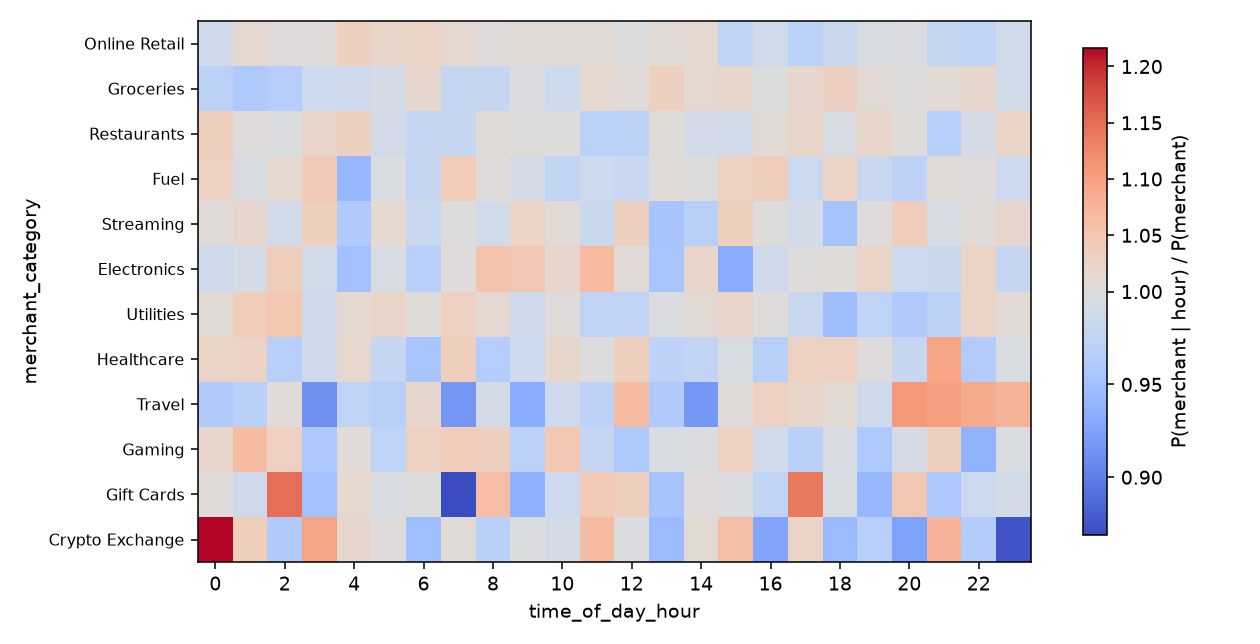

In [8]:
from sklearn.metrics import mutual_info_score

MERCHANT_COL = "merchant_category"
time_cell = region[HOUR_COL].astype(str) + "_" + region[DOW_COL].astype(str)
h_merchant = mutual_info_score(region[MERCHANT_COL], region[MERCHANT_COL])
h_fraud = mutual_info_score(region[TARGET_COLUMN], region[TARGET_COLUMN])

mi_pairs = [
    ("merchant_category x hour", region[MERCHANT_COL], region[HOUR_COL], h_merchant),
    ("merchant_category x day_of_week", region[MERCHANT_COL], region[DOW_COL], h_merchant),
    ("merchant_category x hour_day_cell", region[MERCHANT_COL], time_cell, h_merchant),
    ("hour x is_fraud", region[HOUR_COL], region[TARGET_COLUMN], h_fraud),
    ("day_of_week x is_fraud", region[DOW_COL], region[TARGET_COLUMN], h_fraud),
    ("hour_day_cell x is_fraud", time_cell, region[TARGET_COLUMN], h_fraud),
    ("merchant_category x is_fraud", region[MERCHANT_COL], region[TARGET_COLUMN], h_fraud),
]
mi_rows: list[dict[str, object] | None] = [None] * len(mi_pairs)
for i, (name, left, right, ref_entropy) in enumerate(mi_pairs):
    mi = float(mutual_info_score(left, right))
    mi_rows[i] = {
        "pair": name,
        "mi_nats": mi,
        "reference_entropy": float(ref_entropy),
        "share_explained": mi / float(ref_entropy),
    }
mi_table = pd.DataFrame([row for row in mi_rows if row is not None])
print(f"H(merchant)={h_merchant:.4f} nats, H(is_fraud)={h_fraud:.4f} nats")
print(mi_table.round(5).to_string(index=False))
mi_path = tables_dir / "time_merchant_mutual_information.csv"
mi_table.to_csv(mi_path, index=False)
print("saved", mi_path)
print(DELIMITER_VALUE)

merchant_share = region[MERCHANT_COL].value_counts(normalize=True)
merchant_given_hour = pd.crosstab(region[HOUR_COL], region[MERCHANT_COL], normalize="index")
lift = merchant_given_hour.div(merchant_share, axis=1)
lift = lift.reindex(index=range(24), columns=merchant_share.index)
if lift.isna().to_numpy().any():
    raise ValueError("lift grid has empty hour or merchant cells")
stacked = lift.stack()
best = stacked.idxmax()
worst = stacked.idxmin()
print(f"max lift {stacked.max():.3f} at hour={best[0]}, merchant={best[1]}")
print(f"min lift {stacked.min():.3f} at hour={worst[0]}, merchant={worst[1]}")
lift_path = tables_dir / "merchant_by_hour_lift.csv"
lift.to_csv(lift_path)
print("saved", lift_path)
print(DELIMITER_VALUE)

merchant_given_dow = pd.crosstab(region[DOW_COL], region[MERCHANT_COL], normalize="index")
lift_dow = merchant_given_dow.div(merchant_share, axis=1).reindex(
    index=range(7), columns=merchant_share.index
)
print("lift P(merchant | day_of_week) / P(merchant)")
print(lift_dow.round(3).to_string())
lift_dow_path = tables_dir / "merchant_by_day_lift.csv"
lift_dow.to_csv(lift_dow_path)
print("saved", lift_dow_path)

from matplotlib.colors import TwoSlopeNorm

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="time_cells")
fig, ax = plt.subplots(figsize=(9.0, 4.6))
im = ax.imshow(
    lift.to_numpy(dtype=np.float64).T,
    aspect="auto",
    cmap="coolwarm",
    norm=TwoSlopeNorm(vcenter=1.0),
)
ax.set_xticks(np.arange(0, 24, 2))
ax.set_xlabel(HOUR_COL)
ax.set_yticks(np.arange(len(merchant_share.index)))
ax.set_yticklabels(list(merchant_share.index), fontsize=8)
ax.set_ylabel(MERCHANT_COL)
fig.colorbar(im, ax=ax, shrink=0.9, label="P(merchant | hour) / P(merchant)")
fig.tight_layout()
lift_plot_path = plot_dir / "merchant_by_hour_lift.png"
fig.savefig(lift_plot_path, dpi=140)
print("saved", lift_plot_path)
plt.show()


## Takeaway: time cells

1. **Fraud is independent of the time cell in this region.** Chi-square on the 7 x 24 grid: chi2=150.0, dof=167, p=0.82, Cramer's V=0.016. The "hot" cells (0.5-0.6% vs the 0.28% background) and "cold" cells (0.10%) are consistent with noise given ~10 frauds per cell. Mutual information agrees: hour explains 0.09% of the label entropy, day_of_week ~0.01%, the joint cell 0.64%.

2. **Merchant mix does not depend on time either.** MI(merchant, hour) = 0.0003 nats = 0.015% of the merchant entropy; the 12 x 24 lift grid stays between 0.87 and 1.22, and the extremes are the expected max/min under sampling noise (Crypto Exchange at hour 0 is ~2 SE over background and the largest of 288 cells). The day-of-week lift table sits within ~+-7% almost everywhere. The common-sense "groceries by day, streaming at night" structure is absent; the generator drew them independently.

3. **What this means for the reduction plan.** Inside this region, coarse-binning the time grain loses nothing: there is no signal to lose. The gain is in grouping, since footprints stop degenerating to row level. This says nothing about the alarm region or the higher-score rows; check time signal there before touching the columns globally.

4. **Merchant x fraud is also ~nil here** (MI explains 0.6% of the label entropy), so merging merchant levels is likewise a grouping decision, not a signal decision, inside this region.